### 1a

theta_LS = [ 0.36653876  1.5006948   0.20814339 -1.59632225  0.30487261 -0.1499845
  1.22721903 -0.00566753]
Validation MSE = 0.3457172773966413

Largest training residuals:
Row       x        Residual     Squared residual
 19    -0.3092      -3.5004          12.2529
 40     0.4503      -2.5961           6.7399
 52     0.7238      -2.5163           6.3320
 42     0.5094      -2.2716           5.1600
 11    -0.5673      -1.8059           3.2613
 36     0.2957      -1.6305           2.6586
Share of training SSE from these 6 rows: 82.1%
Legendre: lambda_min = 0.19407839, lambda_max = 61.221536, kappa = 315.44747
Monomial: lambda_min = 0.00050822583, lambda_max = 71.134432, kappa = 139966.19


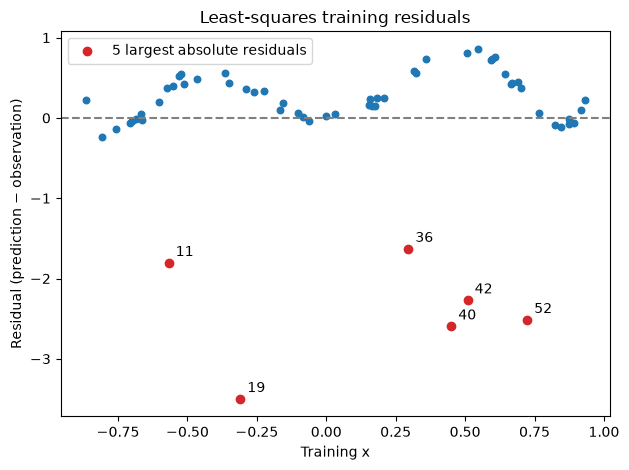

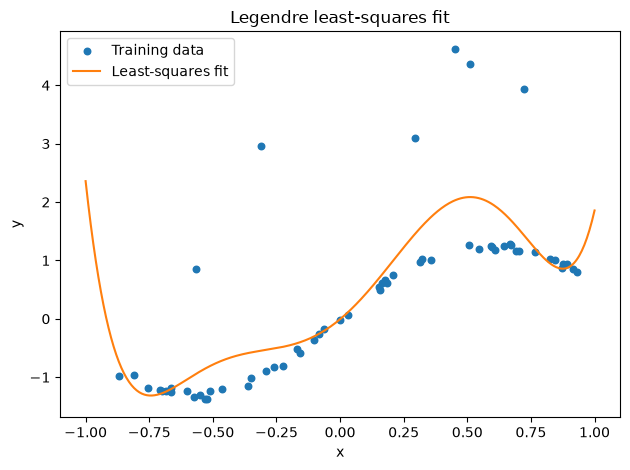

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

data_dir = Path(r".")


def legendre_matrix(x, n=8):
    A = np.empty((len(x), n))
    A[:, 0] = 1.0
    A[:, 1] = x

    for k in range(1, n - 1):
        A[:, k + 1] = (
            (2 * k + 1) * x * A[:, k] - k * A[:, k - 1]
        ) / (k + 1)

    return A


# 1. 用训练数据求最小二乘系数
x_train, b = np.loadtxt(data_dir / "trainingI.dat", unpack=True)
A = legendre_matrix(x_train)
theta_ls = np.linalg.solve(A.T @ A, A.T @ b)

print("theta_LS =", theta_ls)

# 2. 在 [-1, 1] 上计算拟合曲线
x_plot = np.linspace(-1, 1, 400)
y_plot = legendre_matrix(x_plot) @ theta_ls

# 3. 用同一组系数预测验证数据并计算 MSE
x_val, y_val = np.loadtxt(data_dir / "validationI.dat", unpack=True)
y_pred = legendre_matrix(x_val) @ theta_ls
validation_mse = np.mean((y_pred - y_val) ** 2)

print(f"Validation MSE = {validation_mse}")

# 4. 检查训练残差
residuals = A @ theta_ls - b
squared_residuals = residuals ** 2
largest = np.argsort(np.abs(residuals))[::-1][:6]

print("\nLargest training residuals:")
print("Row       x        Residual     Squared residual")
for i in largest:
    print(f"{i + 1:3d}   {x_train[i]:8.4f}   {residuals[i]:10.4f}"
          f"   {squared_residuals[i]:14.4f}")

sse = squared_residuals.sum()
if sse > 0:
    share = squared_residuals[largest].sum() / sse
    print(f"Share of training SSE from these 6 rows: {share:.1%}")

fig_res, ax_res = plt.subplots()
ax_res.scatter(x_train, residuals, s=22)
ax_res.axhline(0, color="grey", linestyle="--")

ax_res.scatter(x_train[largest], residuals[largest],
               color="tab:red", label="6 largest absolute residuals")
for i in largest:
    ax_res.annotate(
        str(i + 1),
        (x_train[i], residuals[i]),
        xytext=(5, 5),
        textcoords="offset points",
    )

ax_res.set(xlabel="Training x", ylabel="Residual (prediction − observation)",
           title="Least-squares training residuals")
ax_res.legend()
fig_res.tight_layout()

# 每一列依次是 1, x, x**2, ..., x**7
A_mono = np.column_stack([x_train**k for k in range(8)])

for name, B in [("Legendre", A), ("Monomial", A_mono)]:
    eigenvalues = np.linalg.eigvalsh(B.T @ B)
    lambda_min = eigenvalues[0]
    lambda_max = eigenvalues[-1]
    kappa = lambda_max / lambda_min

    print(f"{name}: lambda_min = {lambda_min:.8g}, "
          f"lambda_max = {lambda_max:.8g}, kappa = {kappa:.8g}")

# 在同一张图上画训练散点和拟合曲线
fig, ax = plt.subplots()
ax.scatter(x_train, b, s=22, label="Training data")
ax.plot(x_plot, y_plot, color="tab:orange", label="Least-squares fit")
ax.set(xlabel="x", ylabel="y", title="Legendre least-squares fit")
ax.legend()
fig.tight_layout()
plt.show()


### 1a check

In [3]:
# 打印A矩阵检查形式对不对
x = np.array([-1, 0, 1])
A = legendre_matrix(x)

print(A)

[[ 1.     -1.      1.     -1.      1.     -1.      1.     -1.    ]
 [ 1.      0.     -0.5    -0.      0.375   0.     -0.3125 -0.    ]
 [ 1.      1.      1.      1.      1.      1.      1.      1.    ]]


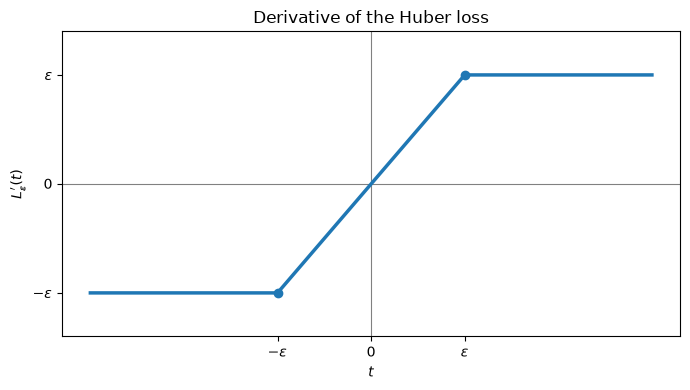

In [3]:
import matplotlib.pyplot as plt
import numpy as np

epsilon = 1.0

# 加入两个拼接点，确保折线恰好在 t = ±epsilon 处转折
t = np.sort(np.r_[np.linspace(-3 * epsilon, 3 * epsilon, 400),
                  -epsilon, epsilon])
derivative = np.clip(t, -epsilon, epsilon)

fig, ax = plt.subplots(figsize=(7, 4))

ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)

ax.plot(t, derivative, color="tab:blue", linewidth=2.5)
ax.scatter([-epsilon, epsilon], [-epsilon, epsilon],
           color="tab:blue", zorder=3)

ax.set_xticks([-epsilon, 0, epsilon], [r"$-\epsilon$", "$0$", r"$\epsilon$"])
ax.set_yticks([-epsilon, 0, epsilon], [r"$-\epsilon$", "$0$", r"$\epsilon$"])
ax.set_ylim(-1.4 * epsilon, 1.4 * epsilon)
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$L_\epsilon'(t)$")
ax.set_title("Derivative of the Huber loss")

fig.tight_layout()
fig.savefig("./figures/1b.png", dpi=300, bbox_inches="tight")
plt.show()

### 1biii

In [4]:
r_ls = A @ theta_ls - b
R = np.linalg.norm(r_ls, ord=np.inf)
print(f"R = {R:.8f}")

for ratio in (1.0, 0.999, 0.99):
    epsilon = ratio * R
    grad = A.T @ np.clip(r_ls, -epsilon, epsilon)
    clipped_rows = np.flatnonzero(np.abs(r_ls) > epsilon) + 1

    print(f"epsilon = {epsilon:.8f}, "
          f"clipped rows = {clipped_rows.tolist()}, "
          f"gradient norm = {np.linalg.norm(grad):.8e}")

R = 3.50041254
epsilon = 3.50041254, clipped rows = [], gradient norm = 1.55640354e-14
epsilon = 3.49691213, clipped rows = [19], gradient norm = 4.37419137e-03
epsilon = 3.46540841, clipped rows = [19], gradient norm = 4.37419137e-02


### 1ci

     epsilon   iterations     validation MSE
       0.001        29208      0.00043093466
  0.00316228        22314      0.00047609158
        0.01         9177      0.00055409182
   0.0316228         5637      0.00026879999
         0.1         4257      0.00028398959
    0.316228         4636       0.0035615623
           1         5105        0.057075031
     3.16228         5306         0.32363649
          10         5304         0.34571726

Best epsilon = 0.031622777
Best validation MSE = 0.00026879999
Outlier rows: [11, 19, 36, 40, 42, 52]
Residual gap: 2.1318 to 0.1324


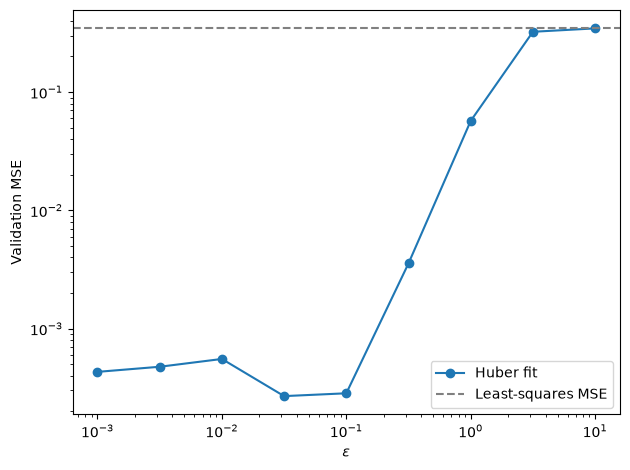

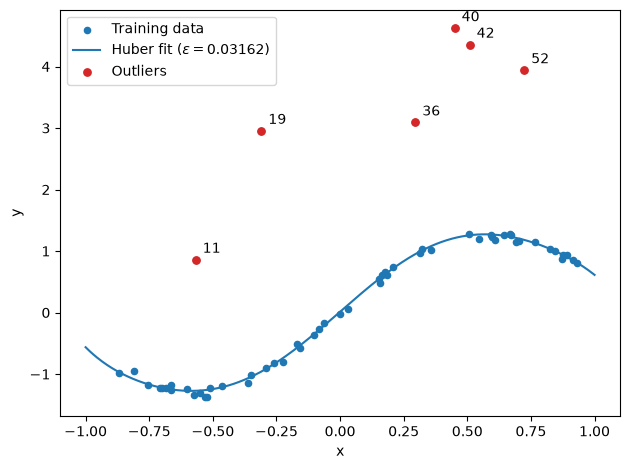

In [5]:
# I.c(i): Huber regression with fixed-step gradient descent
A_val = legendre_matrix(x_val)
ls_mse = np.mean((A_val @ theta_ls - y_val) ** 2)

# 题目指定的固定步长
lambda_max = np.linalg.eigvalsh(A.T @ A)[-1]
step = 1.0 / lambda_max

# 每个 epsilon 都从零开始，用相同的梯度范数容差
tol = 1e-8
max_updates = 100_000


def fit_huber(epsilon):
    theta = np.zeros(A.shape[1])

    for iterations in range(max_updates + 1):
        residuals = A @ theta - b
        grad = A.T @ np.clip(residuals, -epsilon, epsilon)

        if np.linalg.norm(grad) <= tol:
            return theta, iterations

        if iterations < max_updates:
            theta = theta - step * grad

    raise RuntimeError(f"Iteration limit reached for epsilon={epsilon:.6g}")


# 1. 跑九组 epsilon，并记录验证 MSE
epsilons = 10.0 ** np.linspace(-3, 1, 9)
fits = []
mse_values = []

print(f"{'epsilon':>12} {'iterations':>12} {'validation MSE':>18}")

for epsilon in epsilons:
    theta, iterations = fit_huber(epsilon)
    mse = np.mean((A_val @ theta - y_val) ** 2)

    fits.append(theta)
    mse_values.append(mse)
    print(f"{epsilon:12.6g} {iterations:12d} {mse:18.8g}")

best_idx = np.argmin(mse_values)
best_epsilon = epsilons[best_idx]
theta_best = fits[best_idx]

print(f"\nBest epsilon = {best_epsilon:.8g}")
print(f"Best validation MSE = {mse_values[best_idx]:.8g}")

# 2. 画验证 MSE 双对数图，并加入 LS 参考线
fig_mse, ax_mse = plt.subplots()
ax_mse.loglog(epsilons, mse_values, "o-", label="Huber fit")
ax_mse.axhline(ls_mse, color="grey", linestyle="--",
               label="Least-squares MSE")
ax_mse.set(xlabel=r"$\epsilon$", ylabel="Validation MSE")
ax_mse.legend()
fig_mse.tight_layout()
fig_mse.savefig("./figures/1c_1.png", dpi=300, bbox_inches="tight")

# 3. 用最佳拟合的绝对残差识别离群点
# 从大到小排序，在相邻绝对残差的最大间隔处划分
abs_residuals = np.abs(A @ theta_best - b)
order = np.argsort(abs_residuals)[::-1]
sorted_residuals = abs_residuals[order]

gaps = sorted_residuals[:-1] - sorted_residuals[1:]
split = np.argmax(gaps) + 1
outlier_idx = np.sort(order[:split])

print("Outlier rows:", (outlier_idx + 1).tolist())
print(f"Residual gap: {sorted_residuals[split - 1]:.4f} "
      f"to {sorted_residuals[split]:.4f}")

# 4. 画最佳拟合，标注离群点的原始行号
x_grid = np.linspace(-1, 1, 400)
y_grid = legendre_matrix(x_grid) @ theta_best

fig_fit, ax_fit = plt.subplots()
ax_fit.scatter(x_train, b, s=20, label="Training data")
ax_fit.plot(x_grid, y_grid, color="tab:blue",
            label=fr"Huber fit ($\epsilon={best_epsilon:.4g}$)")
ax_fit.scatter(x_train[outlier_idx], b[outlier_idx],
               color="tab:red", s=28, label="Outliers", zorder=3)

for i in outlier_idx:
    ax_fit.annotate(str(i + 1), (x_train[i], b[i]),
                    xytext=(5, 5), textcoords="offset points")

ax_fit.set(xlabel="x", ylabel="y")
ax_fit.legend()
fig_fit.tight_layout()
fig_fit.savefig("./figures/1c_2.png", dpi=300, bbox_inches="tight")

plt.show()

### 1cii

     epsilon    |I|     lambda_min
       0.001      9    0.033119506
  0.00316228      9    0.033119506
        0.01     18    0.094833072
   0.0316228     28     0.14483925
         0.1     52     0.18392448
    0.316228     54     0.19118748
           1     54     0.19118748
     3.16228     59     0.19343947
          10     60     0.19407839


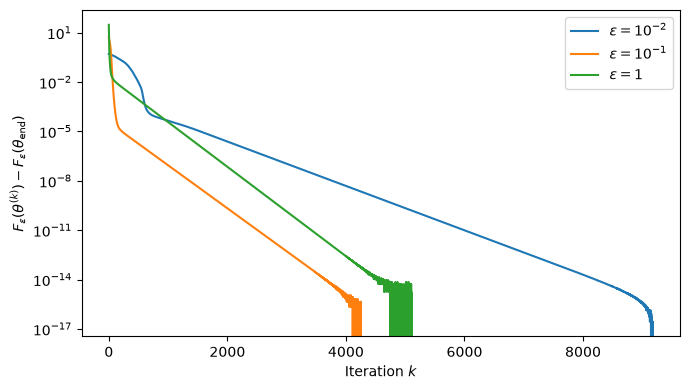

In [8]:
# I.c(ii): 计算九组 epsilon 对应的 |I| 和最小特征值
print(f"{'epsilon':>12} {'|I|':>6} {'lambda_min':>14}")

for epsilon, theta in zip(epsilons, fits):
    residuals = A @ theta - b
    inside = np.abs(residuals) < epsilon
    A_I = A[inside, :]
    lambda_min = np.linalg.eigvalsh(A_I.T @ A_I)[0]

    print(f"{epsilon:12.6g} {inside.sum():6d} {lambda_min:14.8g}")


def huber_value(residuals, epsilon):
    abs_r = np.abs(residuals)
    losses = np.where(
        abs_r <= epsilon,
        0.5 * residuals**2,
        epsilon * (abs_r - 0.5 * epsilon),
    )
    return losses.sum()


def huber_history(epsilon):
    """从零开始运行梯度法，记录每一步的 Huber 目标值。"""
    theta = np.zeros(A.shape[1])
    history = []

    for k in range(max_updates + 1):
        residuals = A @ theta - b
        history.append(huber_value(residuals, epsilon))

        grad = A.T @ np.clip(residuals, -epsilon, epsilon)
        # 1 b ii norm(grad(f)) = 0 ==> global min
        if np.linalg.norm(grad) <= tol:
            return np.asarray(history)

        if k < max_updates:
            theta = theta - step * grad

    raise RuntimeError(f"Iteration limit reached for epsilon={epsilon:g}")


fig, ax = plt.subplots(figsize=(7, 4))

for epsilon, label in [
    (1e-2, r"$\epsilon=10^{-2}$"),
    (1e-1, r"$\epsilon=10^{-1}$"),
    (1.0, r"$\epsilon=1$"),
]:
    history = huber_history(epsilon)
    k = np.arange(len(history))
    # 最后一个算的就是theta*的近似值
    gap = history - history[-1]

    ax.semilogy(k, gap, label=label)

ax.set_xlabel(r"Iteration $k$")
ax.set_ylabel(
    r"$F_\epsilon(\theta^{(k)})-F_\epsilon(\theta_{\mathrm{end}})$"
)
ax.legend()
fig.tight_layout()
fig.savefig("./figures/1c_3.png", dpi=300, bbox_inches="tight")
plt.show()